In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator
from IPython.display import display

DATA_DIR = next((p for p in [Path.cwd(), Path.cwd() / 'supp9', Path.cwd() / 'analysis' / 'supp9']
                 if (p / 'number_ARGs_per_sample_SR.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Run this notebook from supp9, analysis, or the repository root.')
plt.rcParams.update({
    'font.family': 'Arial', 'font.size': 8, 'axes.labelsize': 9,
    'axes.titlesize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'axes.linewidth': 0.8,
    'xtick.major.width': 0.8, 'ytick.major.width': 0.8,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'svg.fonttype': 'none',
})

def load_samples(platform):
    df = pd.read_csv(DATA_DIR / f'number_ARGs_per_sample_{platform}.csv', index_col=0)
    # The updated SR CSV reports distinct-centroid counts under this column.
    if platform == 'SR':
        df['n_ARGs'] = df['n_ARGs_centroids']
    assert df['sample'].is_unique, 'Duplicate sample IDs'
    for col in ['sum_len', 'Q2']:
        df[col] = pd.to_numeric(df[col], errors='raise')
        assert np.isfinite(df[col]).all() and (df[col] > 0).all(), col
    assert 'n_ARGs' in df, f'{platform}: missing ARG counts'
    if 'n_ARGs' in df:
        df['n_ARGs'] = pd.to_numeric(df['n_ARGs'], errors='raise')
        assert np.isfinite(df['n_ARGs']).all() and (df['n_ARGs'] >= 0).all()
        assert (df['n_ARGs'] % 1 == 0).all(), 'ARG counts must be integers'
    return df

data = {platform: load_samples(platform) for platform in ['SR', 'LR']}
display(pd.DataFrame([{'platform': p, 'samples': len(d), 'ARG counts available': 'n_ARGs' in d}
                      for p, d in data.items()]))


C:\Users\admin\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
  platform  samples  ARG counts available
0       SR       58                  True
1       LR       58                  True


In [2]:
cmap = plt.get_cmap('YlOrBr')

def bubble_area(count, count_min, count_max):
    fraction = (np.asarray(count) - count_min) / max(count_max - count_min, 1)
    return 9.0 + np.clip(fraction, 0, 1) * (324.0 - 9.0)

def plot_samples(df, platform):
    has_counts = 'n_ARGs' in df
    count_min, count_max = df['n_ARGs'].min(), df['n_ARGs'].max()
    norm = Normalize(vmin=0, vmax=count_max)
    fig, ax = plt.subplots(figsize=(5.1, 3.8))
    fig.subplots_adjust(left=0.14, bottom=0.18, right=0.73, top=0.92)
    x, y = np.log(df['sum_len']), np.log(df['Q2'])
    if has_counts:
        points = ax.scatter(x, y, s=bubble_area(df['n_ARGs'], count_min, count_max), c=df['n_ARGs'],
                            cmap=cmap, norm=norm, marker='o', edgecolors='#373737',
                            linewidths=0.5, alpha=0.85)
        cax = fig.add_axes([0.80, 0.52, 0.025, 0.33])
        cb = fig.colorbar(points, cax=cax)
        cb.set_label('Number of ARGs', labelpad=6)
        cb.outline.set_linewidth(0.5)
        cb.ax.tick_params(width=0.5, length=2)
        # Four reference sizes; individual samples retain continuous count values.
        levels = [50, 100, 150, 200] if platform == 'SR' else [400, 600, 800, 1000]
        handles = [ax.scatter([], [], s=bubble_area(v, count_min, count_max), color=cmap(norm(v)),
                              edgecolors='#373737', linewidths=0.5, alpha=0.85) for v in levels]
        ax.legend(handles, [f'{v:,.0f}' for v in levels], title='Number of ARGs',
                  loc='upper left', bbox_to_anchor=(1.07, 0.43), frameon=False,
                  labelspacing=1.3, borderpad=0, handletextpad=0.8)
        name = f'{platform}_n_args_depth_q2.svg'
    else:
        ax.scatter(x, y, s=25, color='#e6ab02', marker='o',
                   edgecolors='#373737', linewidths=0.5, alpha=0.85)
        fig.text(0.77, 0.75, 'ARG counts\nunavailable;\nuniform points', fontsize=8, va='top')
        name = f'{platform}_n_args_depth_q2_pending_counts.svg'
    ax.set(xlabel='ln(Total number of bp in assembly)', ylabel='ln(Median contig length)',
           title=platform if has_counts else f'{platform} (coordinate preview)')
    ax.grid(False, which='both', axis='both')
    ax.tick_params(direction='out', length=3)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.margins(x=0.10, y=0.12)
    
    for idx in df.index[x < 20]:
        ax.annotate(df.loc[idx, 'sample'], (x.loc[idx], y.loc[idx]),
                    xytext=(5, 6), textcoords='offset points', fontsize=7)
    plt.show()
    return fig


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MultipleLocator
from matplotlib.patches import Patch

ALIGN_DIR = next(p for p in [Path.cwd(), Path.cwd() / 'supp9',
                            Path.cwd() / 'analysis' / 'supp9']
                 if (p / 'sample-to-sample-alignment-quality-SR-to-LR-summary.csv').is_file())
alignment = pd.read_csv(ALIGN_DIR / 'sample-to-sample-alignment-quality-SR-to-LR-summary.csv')


C:\Users\admin\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [ ]:
totals = alignment.groupby('class')['N'].first()


Validated 16 ARG classes and 7,313 genes.


In [ ]:
class_order = alignment['class'].drop_duplicates().tolist()[::-1]
status_order = ['H', 'L', 'U']
counts = alignment.pivot(index='class', columns='label', values='n')
counts = counts.reindex(index=class_order, columns=status_order).fillna(0).astype(int)
rates = alignment.pivot(index='class', columns='label', values='r')
rates = rates.reindex(index=class_order, columns=status_order).fillna(0)
totals = totals.reindex(class_order)
status_names = {'H': 'High-quality alignment', 'L': 'Low-quality alignment', 'U': 'Unaligned'}
status_colors = {'H': '#a6761d', 'L': '#66a61e', 'U': '#e7298a'}


In [4]:
plt.rcParams.update({
    'font.family': 'Arial', 'font.size': 8, 'axes.labelsize': 9,
    'axes.titlesize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'axes.linewidth': 0.8,
    'xtick.major.width': 0.8, 'ytick.major.width': 0.8,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'svg.fonttype': 'none',
})
fig_alignment, axes_alignment = plt.subplots(1, 2, figsize=(5.3, 4.8), sharey=True,
                                            gridspec_kw={'width_ratios': [0.65, 1]})
fig_alignment.subplots_adjust(left=0.325, right=0.97, bottom=0.12, top=0.86, wspace=0.18)
y = np.arange(len(class_order))


In [5]:
for ax, values in zip(axes_alignment, [rates, counts]):
    left = np.zeros(len(class_order))
    for status in status_order:
        ax.barh(y, values[status], left=left, height=0.70,
                color=status_colors[status], edgecolor='white', linewidth=0.25)
        left += values[status].to_numpy()
    ax.grid(False, which='both', axis='both')
    ax.tick_params(axis='x', direction='out', length=3)
    ax.tick_params(axis='y', length=0)
    ax.set_ylim(len(class_order) - 0.4, -0.6)
axes_alignment[0].set_yticks(y)
axes_alignment[0].set_yticklabels(class_order)
axes_alignment[1].tick_params(axis='y', labelleft=False)


In [6]:
axes_alignment[0].set(xlim=(0, 1), xlabel='Proportion of SR ARGs')
axes_alignment[0].xaxis.set_major_locator(MultipleLocator(0.5))
axes_alignment[0].xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
axes_alignment[1].set(xlim=(0, 4400), xlabel='Number of SR ARGs')
axes_alignment[1].xaxis.set_major_locator(MultipleLocator(1000))
for row, total in enumerate(totals):
    axes_alignment[1].annotate(f'{int(total):,}', (total, row), xytext=(3, 0),
                               textcoords='offset points', va='center', fontsize=7)
handles = [Patch(facecolor=status_colors[s], label=status_names[s]) for s in status_order]
fig_alignment.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.63, 1.0),
                     ncol=2, frameon=False, handlelength=1.1, columnspacing=1.4)


Saved SR_gene_detection_undetection_rates_and_number_of_ARGs.svg
<alignment>:5: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


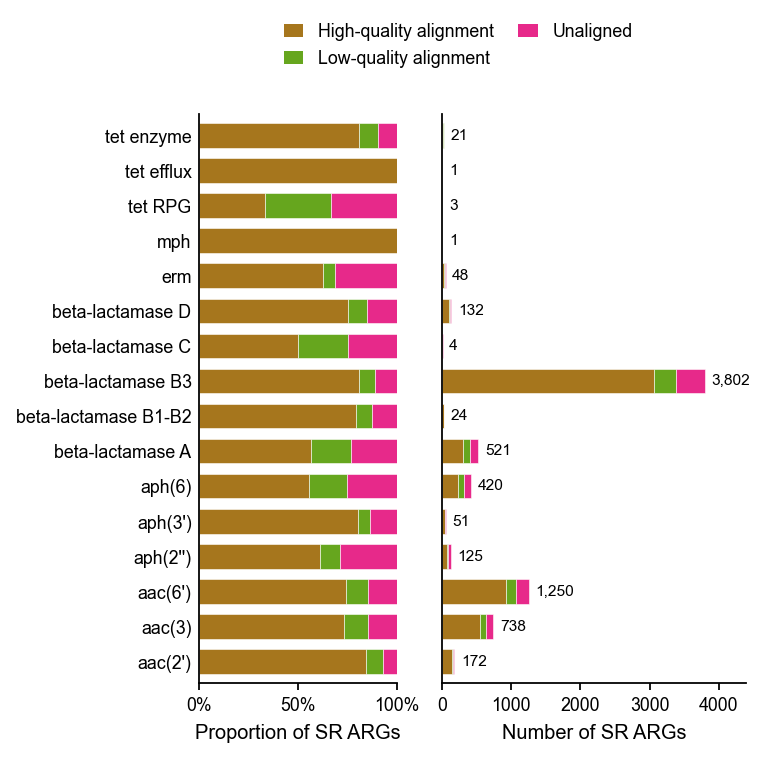

In [ ]:
plt.show()


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MultipleLocator
from matplotlib.lines import Line2D
from scipy.stats import t

DETECT_DIR = next(p for p in [Path.cwd(), Path.cwd() / 'supp9',
                             Path.cwd() / 'analysis' / 'supp9']
                  if (p / 'Detection_rate_80ID_80Coverage_of_LR_in_SR.csv').is_file())
detection = pd.read_csv(DETECT_DIR / 'Detection_rate_80ID_80Coverage_of_LR_in_SR.csv', index_col=0)


C:\Users\admin\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [ ]:
fit_data = detection.loc[detection['class'].ne('qnr')].copy()
x_fit = fit_data['mean_len'].to_numpy()
y_fit = fit_data['detect_rate80'].to_numpy()
design = np.column_stack([np.ones(len(x_fit)), x_fit])
coef = np.linalg.lstsq(design, y_fit, rcond=None)[0]
dof = len(x_fit) - 2
residual_sd = np.sqrt(np.sum((y_fit - design @ coef) ** 2) / dof)


17 classes plotted; 16 classes in the linear model.


In [3]:
x_line = np.linspace(x_fit.min(), x_fit.max(), 200)
y_line = coef[0] + coef[1] * x_line
sxx = np.sum((x_fit - x_fit.mean()) ** 2)
mean_se = residual_sd * np.sqrt(1 / len(x_fit) + (x_line - x_fit.mean()) ** 2 / sxx)
ci_half = t.ppf(0.975, dof) * mean_se

def detection_area(n):
    # Match the original ggplot square-root size mapping, scaled to this panel.
    # Diameters span 2–21 pt; scatter expects squared sizes (pt²).
    low, high = detection['n_lr'].min(), detection['n_lr'].max()
    fraction = (np.asarray(n) - low) / (high - low)
    return (2 + 19 * np.sqrt(np.clip(fraction, 0, 1))) ** 2

included_color, excluded_color = '#666666', '#a6761d'


In [4]:
plt.rcParams.update({
    'font.family': 'Arial', 'font.size': 8, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'axes.linewidth': 0.8, 'xtick.major.width': 0.8, 'ytick.major.width': 0.8,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'svg.fonttype': 'none',
})
fig_detection, ax_detection = plt.subplots(figsize=(6.4, 4.5))
fig_detection.subplots_adjust(left=0.12, right=0.76, bottom=0.15, top=0.96)
ax_detection.fill_between(x_line, y_line - ci_half, y_line + ci_half,
                          color='#d9d9d9', alpha=0.65, linewidth=0, zorder=1)
ax_detection.plot(x_line, y_line, '--', color='#666666', linewidth=1, zorder=2)


In [5]:
for included, color in [(True, included_color), (False, excluded_color)]:
    part = detection.loc[detection['class'].ne('qnr').eq(included)]
    ax_detection.scatter(part['mean_len'], part['detect_rate80'],
                         s=detection_area(part['n_lr']), color=color,
                         edgecolors=color, linewidths=0.5, alpha=0.7, zorder=3)
ax_detection.set(xlim=(100, 720), ylim=(-0.006, 0.15),
                 xlabel='Mean gene length (aa)',
                 ylabel='Detection rate in SR (80% identity / coverage)')
ax_detection.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_detection.yaxis.set_major_locator(MultipleLocator(0.03))
ax_detection.xaxis.set_major_locator(MultipleLocator(100))
ax_detection.tick_params(direction='out', length=3)
ax_detection.grid(False, which='both', axis='both')


In [ ]:
# Offsets in points: dx, dy, horizontal alignment, vertical alignment.
label_offsets = {
    "aac(6')": (-6, 9, 'right', 'bottom'), "aac(2')": (5, 5, 'left', 'bottom'),
    "aac(3)": (6, 5, 'left', 'bottom'), "aph(3')": (-6, 1, 'right', 'center'),
    'erm': (5, 8, 'left', 'bottom'), 'beta-lactamase A': (8, 8, 'left', 'bottom'),
    'tet enzyme': (6, 0, 'left', 'center'), "aph(2'')": (18, 0, 'left', 'center'),
    'aph(6)': (-8, 4, 'right', 'bottom'), 'beta-lactamase D': (-8, -7, 'right', 'top'),
    'beta-lactamase B3': (18, -7, 'left', 'top'), 'tet efflux': (6, 3, 'left', 'bottom'),
    'beta-lactamase B1-B2': (6, 2, 'left', 'bottom'),
    'beta-lactamase C': (6, -2, 'left', 'top'), 'mph': (6, -2, 'left', 'top'),
    'tet RPG': (0, 6, 'center', 'bottom'), 'qnr': (5, 4, 'left', 'bottom'),
}


In [7]:
detection_texts = []
for _, row in detection.iterrows():
    dx, dy, ha, va = label_offsets[row['class']]
    text = ax_detection.annotate(row['class'], (row['mean_len'], row['detect_rate80']),
                                 xytext=(dx, dy), textcoords='offset points',
                                 fontsize=7, ha=ha, va=va, zorder=4)
    detection_texts.append(text)
model_handles = [Line2D([], [], marker='o', linestyle='none', color=color,
                        markersize=4, label=label)
                 for color, label in [(included_color, 'Included'), (excluded_color, 'Excluded (qnr)')]]
model_legend = ax_detection.legend(handles=model_handles, title='Linear model', frameon=False,
                                   loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
ax_detection.add_artist(model_legend)


Saved Detection_LR_genes_in_SR_sequencing.svg
<detection>:12: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


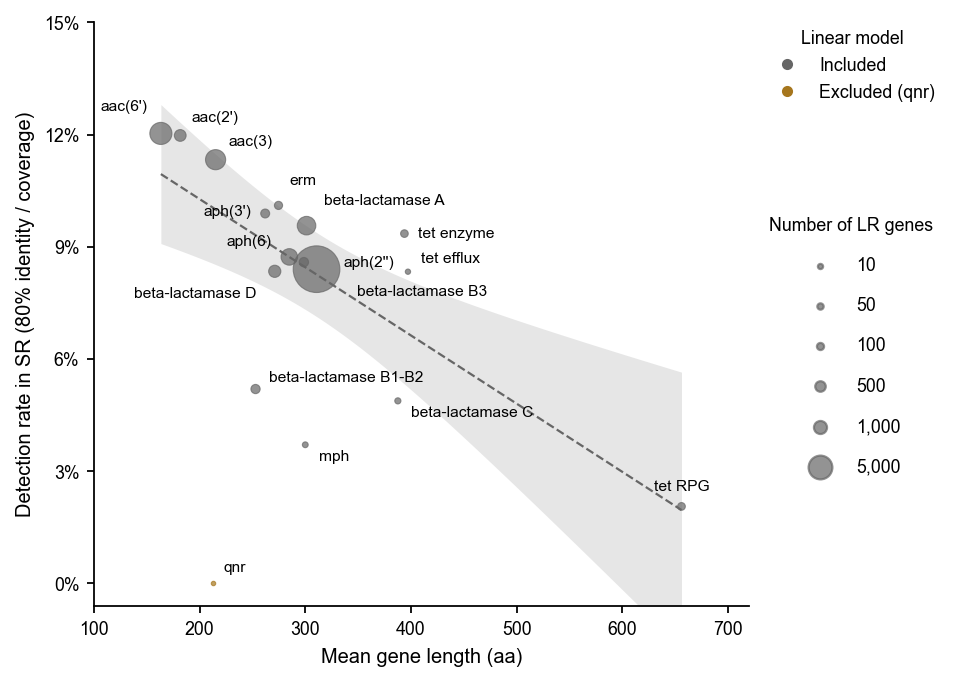

In [ ]:
size_levels = [10, 50, 100, 500, 1000, 5000]
size_handles = [plt.scatter([], [], s=detection_area(n), color=included_color, alpha=0.7)
                for n in size_levels]
ax_detection.legend(size_handles, [f'{n:,}' for n in size_levels], title='Number of LR genes',
                    frameon=False, loc='upper left', bbox_to_anchor=(1.02, 0.68),
                    borderaxespad=0, labelspacing=1.25, handletextpad=1)
plt.show()


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from openpyxl import load_workbook

ARG_DIR = Path('../../resource_generation/12_ARGs_fARGene')


In [2]:
hits = pd.read_csv(ARG_DIR / 'contigs' / 'closest_hits_orfs_amino.tsv',
                   sep='\t', header=None, usecols=[0, 1], names=['orf', 'centroid'])
centroids = pd.read_csv(ARG_DIR / 'contigs' / 'orfs-amino-centroids.txt',
                        header=None, names=['orf'])['orf']
metadata_book = load_workbook(ARG_DIR / 'supp1_sample_metadata.xlsx', read_only=True, data_only=True)
metadata_rows = metadata_book['sample_metadata'].values
sample_metadata = pd.DataFrame(metadata_rows, columns=next(metadata_rows))
metadata_book.close()
sample_metadata['Sample_id'] = sample_metadata['Sample_id'].str.replace('ample', '', regex=False)


In [3]:
arg_genes = hits.copy()
representatives = arg_genes['orf'].isin(centroids)
arg_genes.loc[representatives, 'centroid'] = arg_genes.loc[representatives, 'orf']
arg_genes['sample'] = arg_genes['orf'].str.split('@@@').str[0]
arg_genes['hmm'] = arg_genes['centroid'].str.split('@@@').str[1]
arg_genes = arg_genes.merge(sample_metadata[['Sample_id', 'City']],
                            left_on='sample', right_on='Sample_id', how='left', validate='many_to_one')


sample
s11    603
s4     591
dtype: int64


In [4]:
class_definitions = {
    'aminoglycoside': {'aac2p': "aac(2')", 'aac3_1': 'aac(3)', 'aac3_2': 'aac(3)',
        'aac6p_1': "aac(6')", 'aac6p_2': "aac(6')", 'aac6p_3': "aac(6')",
        'aph2b': "aph(2'')", 'aph3p': "aph(3')", 'aph6p': 'aph(6)'},
    'beta-lactamase': {'class_a': 'A', 'class_b1_b2': 'B1B2', 'class_b3': 'B3',
        'class_c': 'C', 'class_d1': 'D', 'class_d2': 'D'},
    'macrolide': {'erm_1': 'erm', 'erm_2': 'erm', 'mph': 'mph'},
    'tetracycline': {'tet_efflux': 'efflux', 'tet_enzyme': 'enzyme', 'tet_rpg': 'RPG'},
    'quinolone': {'qnr': 'qnr'},
}
class_map = {hmm: label for group in class_definitions.values() for hmm, label in group.items()}
group_map = {hmm: group for group, mapping in class_definitions.items() for hmm in mapping}
arg_genes['class'] = arg_genes['hmm'].map(class_map)
arg_genes['hclass'] = arg_genes['hmm'].map(group_map)


In [5]:
city_order = ['Nanjing', 'Shanghai']
unique_genes = arg_genes.drop_duplicates(['City', 'centroid'])
unique_genes = unique_genes.sort_values(['City', 'centroid'], kind='stable')
unique_genes = unique_genes.drop_duplicates('centroid')
class_counts = unique_genes.groupby(['hclass', 'class', 'City']).size().rename('n').reset_index()

Included 58 samples, 38,952 gene records, and 16,249 distinct ARG clusters.


In [6]:
plt.rcParams.update({
    'font.family': 'Arial', 'font.size': 8, 'axes.labelsize': 9, 'axes.titlesize': 8,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'axes.linewidth': 0.8, 'xtick.major.width': 0.8, 'ytick.major.width': 0.8,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'svg.fonttype': 'none',
    'hatch.linewidth': 0.4,
})
group_colors = dict(zip(class_definitions, ['#1b9e77', '#e6ab02', '#d95f02', '#7570b3', '#e7298a']))
city_hatches = {'Nanjing': '///', 'Shanghai': '..'}
fig_classes, axes_classes = plt.subplots(1, 5, figsize=(7.5, 3.3),
    gridspec_kw={'width_ratios': [6, 5, 2.7, 3.5, 2.4]})
fig_classes.subplots_adjust(left=0.08, right=0.99, bottom=0.30, top=0.85, wspace=0.70)


In [7]:
for ax, group in zip(axes_classes, class_definitions):
    labels = list(dict.fromkeys(class_definitions[group].values()))
    panel = class_counts.loc[class_counts['hclass'].eq(group)]
    panel = panel.pivot(index='class', columns='City', values='n')
    panel = panel.reindex(index=labels, columns=city_order).fillna(0)
    x = np.arange(len(labels))
    for city, shift in zip(city_order, [-0.2, 0.2]):
        ax.bar(x + shift, panel[city], width=0.36, color=group_colors[group],
               edgecolor='#373737', linewidth=0.45, hatch=city_hatches[city])
    ax.set_title(group, pad=10)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90)
    ax.set_ylim(0, max(1, panel.to_numpy().max()) * 1.12)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
    ax.tick_params(direction='out', length=2.5)
    ax.grid(False, which='both', axis='both')
    if group in ['aminoglycoside', 'macrolide', 'quinolone']:
        for tick in ax.get_xticklabels():
            tick.set_fontstyle('italic')


Saved supp9.svg; s4 and s11 retained before all counting steps.
<ARG classes>:10: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


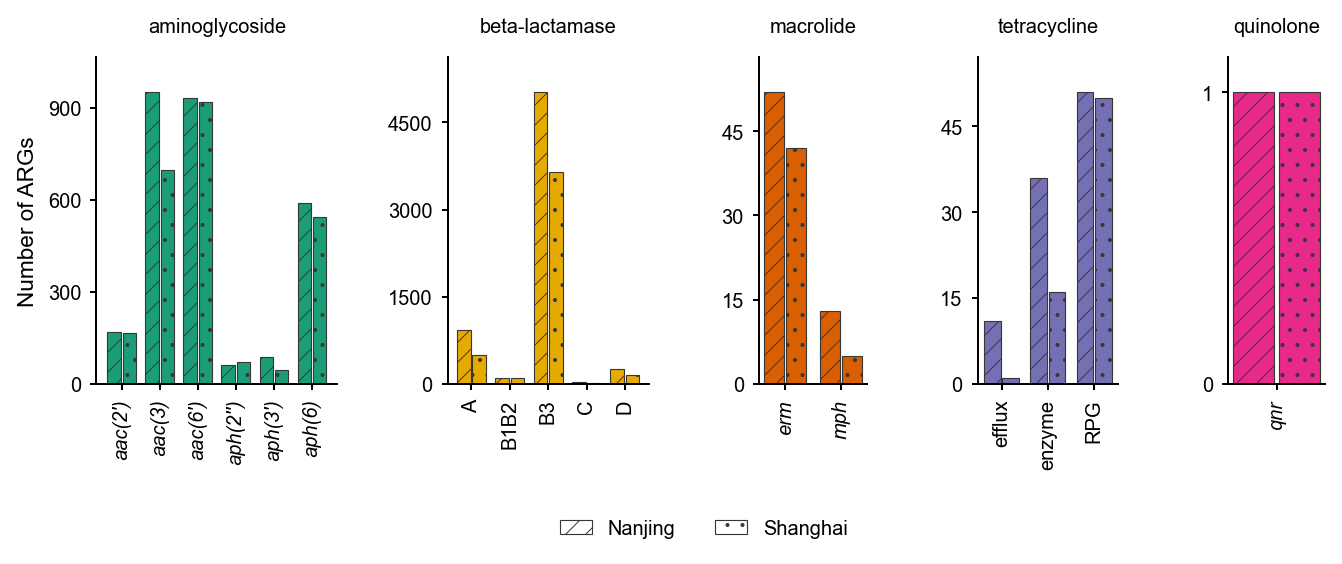

In [ ]:
axes_classes[0].set_ylabel('Number of ARGs')
city_handles = [Patch(facecolor='white', edgecolor='#373737', linewidth=0.45,
                      hatch=city_hatches[city], label=city) for city in city_order]
fig_classes.legend(handles=city_handles, loc='lower center', ncol=2,
                    frameon=False, bbox_to_anchor=(0.53, 0.01), handlelength=1.6)
plt.show()